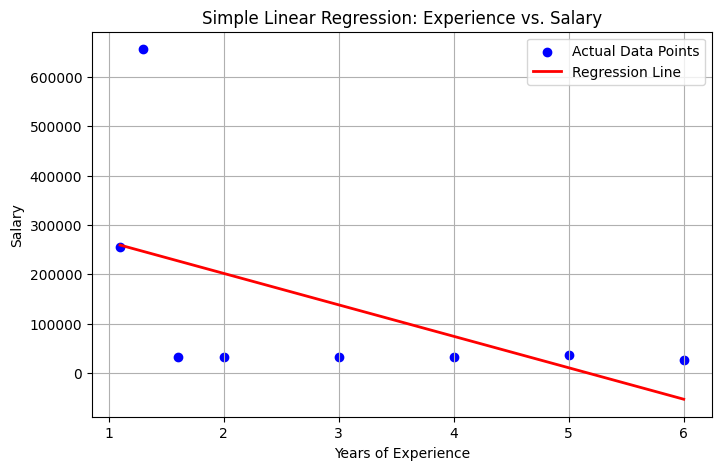

Intercept (c): 329429.47


In [3]:
# QUESTION 1 - implement linear regression on a dataset and visualize the regression line
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Load the dataset
data = pd.read_csv('salary_data.csv')

# 2. Define independent (X) and dependent (y) variables
X = data[['years of Experience']]  # Features must be a 2D DataFrame
y = data['salary']             # Target variable

# 3. Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X, y)

# 4. Generate predictions using the model
y_pred = model.predict(X)

# 5. Visualize the data points and the regression line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', label='Actual Data Points')
plt.plot(X, y_pred, color='red', linewidth=2, label='Regression Line')
plt.title('Simple Linear Regression: Experience vs. Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

# Print the model parameters
print(f"Intercept (c): {model.intercept_:.2f}")



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Prediction for new candidate (1 = Admitted, 0 = Rejected): 1


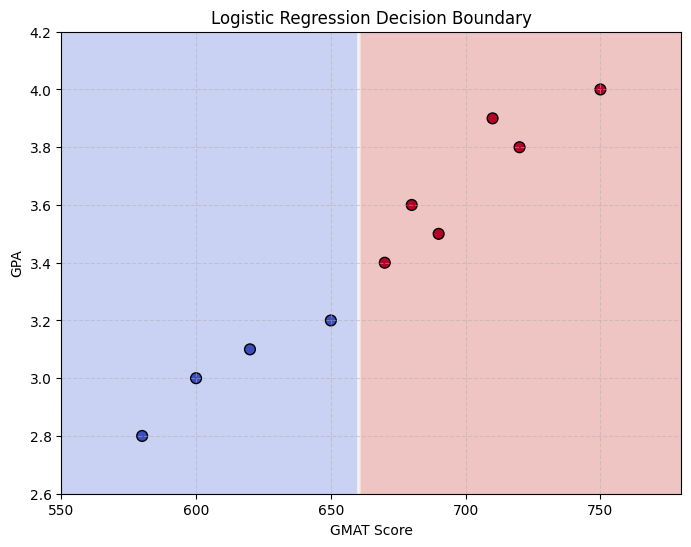

In [4]:
## QUESTION 2 -Implement logistic regression on binary classification dataset and plot decision boundary

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# 1. Create a sample dataset
data = {
    'gmat': [650, 720, 580, 690, 710, 600, 670, 750, 620, 680],
    'gpa': [3.2, 3.8, 2.8, 3.5, 3.9, 3.0, 3.4, 4.0, 3.1, 3.6],
    'work_experience': [2, 5, 1, 3, 6, 2, 4, 7, 2, 4],
    'admitted': [0, 1, 0, 1, 1, 0, 1, 1, 0, 1]
}
df = pd.DataFrame(data)

# 2. Define features (X) and target (y)
X = df[['gmat', 'gpa', 'work_experience']]
y = df['admitted']

# 3. Train Logistic Regression model
model = LogisticRegression()
model.fit(X, y)

# 4. Predict for a new candidate (GMAT: 700, GPA: 3.6, Work Exp: 4 years)
new_candidate = [[700, 3.6, 4]]
prediction = model.predict(new_candidate)
print("Prediction for new candidate (1 = Admitted, 0 = Rejected):", prediction[0])

# 5. Plot 2D Decision Boundary (using GMAT and GPA for visualization)
X_2d = df[['gmat', 'gpa']]
model_2d = LogisticRegression().fit(X_2d, y)

# Create a mesh grid for plotting
xx, yy = np.meshgrid(
    np.linspace(df['gmat'].min() - 30, df['gmat'].max() + 30, 100),
    np.linspace(df['gpa'].min() - 0.2, df['gpa'].max() + 0.2, 100)
)
Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# Draw plot
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(df['gmat'], df['gpa'], c=y, cmap=plt.cm.coolwarm, edgecolors='k', s=60)
plt.xlabel('GMAT Score')
plt.ylabel('GPA')
plt.title('Logistic Regression Decision Boundary')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


--- Evaluation Metrics ---
Accuracy: 1.00

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



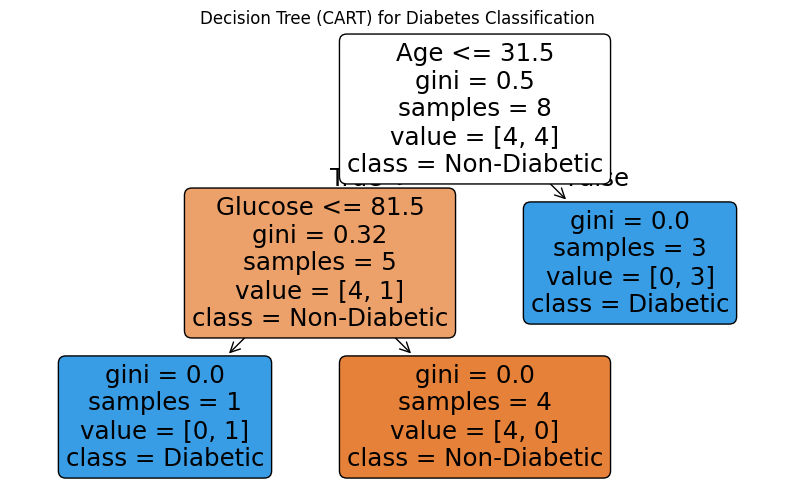

In [5]:
# QUESTION 3 - Implement and Evaluate the performance of decision tree ID3/cart classifier for any given data set
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# 1. Create a sample Diabetes-related dataset (Binary Classification)
# Outcome: 1 = Diabetic, 0 = Non-Diabetic
data = {
    'Glucose': [148, 85, 183, 89, 137, 116, 78, 115, 197, 125, 110, 168],
    'BMI': [33.6, 26.6, 23.3, 28.1, 43.1, 25.6, 31.0, 35.3, 30.5, 32.3, 27.0, 38.2],
    'Age': [50, 31, 32, 21, 33, 30, 26, 29, 53, 37, 24, 45],
    'Outcome': [1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1]
}
df = pd.DataFrame(data)

# 2. Define Features (X) and Target (y)
X = df[['Glucose', 'BMI', 'Age']]
y = df['Outcome']

# Split into Training and Testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Implement & Train CART Decision Tree Classifier
# (criterion='gini' implements the CART algorithm)
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
clf.fit(X_train, y_train)

# 4. Evaluate Performance
y_pred = clf.predict(X_test)

print("--- Evaluation Metrics ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 5. Plot the Decision Tree
plt.figure(figsize=(10, 6))
plot_tree(
    clf,
    feature_names=['Glucose', 'BMI', 'Age'],
    class_names=['Non-Diabetic', 'Diabetic'],
    filled=True,
    rounded=True
)
plt.title("Decision Tree (CART) for Diabetes Classification")
plt.show()


[[29.6 66.8]
 [43.2 16.7]
 [55.1 46.1]]


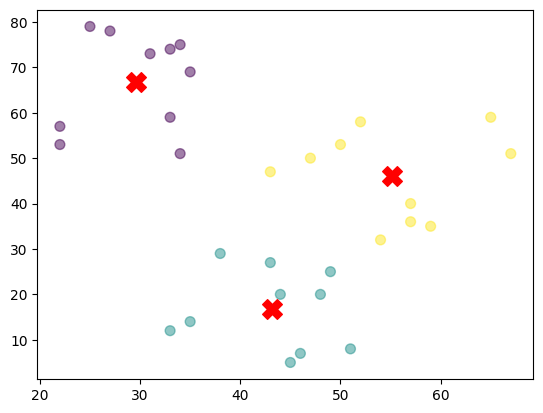

In [6]:
# Q4. Implement k means clustering on a point dataset and visualize and evaluate clusters

from pandas import DataFrame
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

Data = {
    'x': [25,34,22,27,33,33,31,22,35,34,67,54,57,43,50,57,59,52,65,47,49,48,35,33,44,45,38,43,51,46],
    'y': [79,51,53,78,59,74,73,57,69,75,51,32,40,47,53,36,35,58,59,50,25,20,14,12,20,5,29,27,8,7]
}
df = DataFrame(Data, columns=['x', 'y'])

# K-means Clustering (added n_init=10 to avoid future deprecation warnings)
kmeans = KMeans(n_clusters=3, n_init=10).fit(df)

centroids = kmeans.cluster_centers_

print(centroids)

# Plot data points
plt.scatter(df['x'], df['y'], c=kmeans.labels_.astype(float), s=50, alpha=0.5)

# FIXED: Changed centroids[:, 0) to centroids[:, 0]
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X')

plt.show()


[1 2 1 0 0 0]


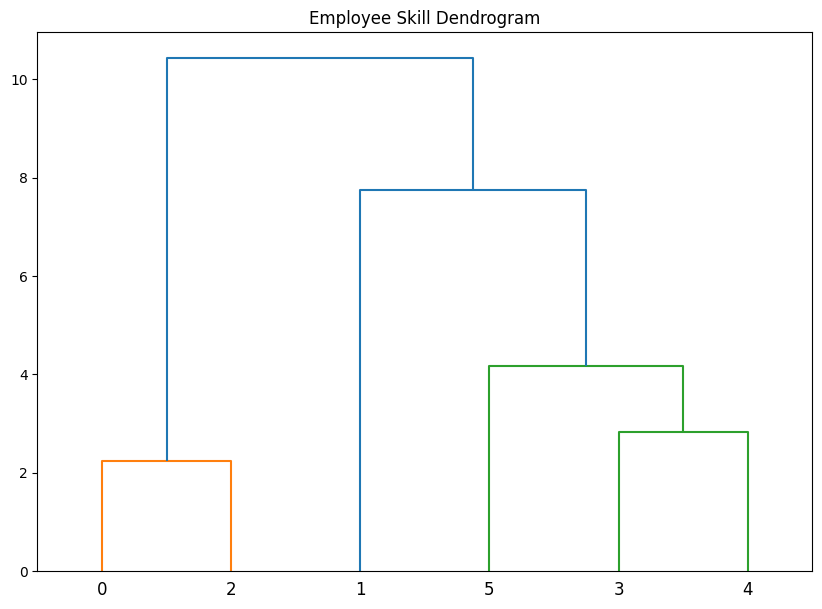

In [9]:
# Q5. implement hierarchical clustering on a dataset and plot dendogram

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Defined with lowercase 'x'
x = np.array([[2,8],[8,15],[3,6],[6,9],[8,7],[10,10]])

# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

# Added '=' for assignment and instantiation
cluster = AgglomerativeClustering(
    n_clusters=3,
    metric='euclidean',
    linkage='ward'
)

# Used lowercase 'x' to match the variable definition
cluster.fit_predict(x)
print(cluster.labels_)

# Drawing Dendrograms
import scipy.cluster.hierarchy as shc

plt.figure(figsize=(10, 7))
plt.title("Employee Skill Dendrogram")

# Added '=' for dendrogram assignment and used lowercase 'x'
dend = shc.dendrogram(shc.linkage(x, method='ward'))
plt.show()


Cluster labels: [ 0  0  0  0  0  0  1  1  1  1  1  1 -1]


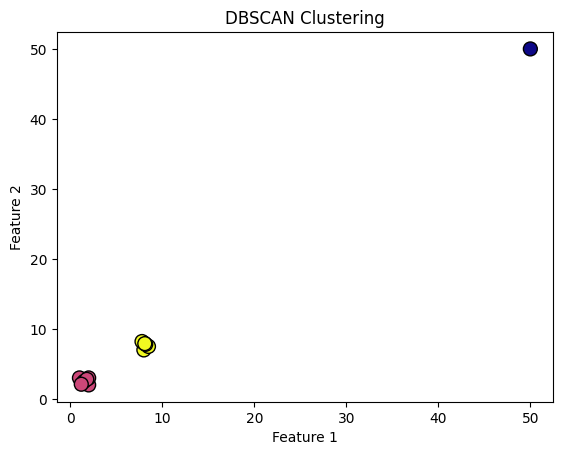

Silhouette Score: 0.91


In [10]:
#Q6. Implement DBSCAN clustering on a dataset and visulaize and evaluate the clusters

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Sample dataset with two clear clusters and an isolated noise point [50, 50]
X = np.array([
    [1, 3], [2, 2], [2, 3], [1.5, 2.5], [1.8, 2.8], [1.2, 2.1],
    [8, 7], [8, 8], [8.5, 7.5], [7.8, 8.2], [8.2, 7.8], [8.1, 7.9],
    [50, 50]
])

# Create and fit DBSCAN model (fixed hyphens to '=' and fixed parameter name)
dbscan = DBSCAN(eps=3, min_samples=2)
dbscan.fit(X)

# Get cluster labels (-1 = noise)
labels = dbscan.labels_
print("Cluster labels:", labels)

# Plot clusters (fixed c=labels, added closing quote for cmap, fixed s=100)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='plasma', s=100, edgecolors='k')
plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Evaluate with Silhouette Score (excluding noise points -1 to avoid errors)
valid_mask = labels != -1
if len(set(labels[valid_mask])) > 1:
    score = silhouette_score(X[valid_mask], labels[valid_mask])
    print(f"Silhouette Score: {score:.2f}")
else:
    print("Silhouette Score: Not enough clusters formed for evaluation.")


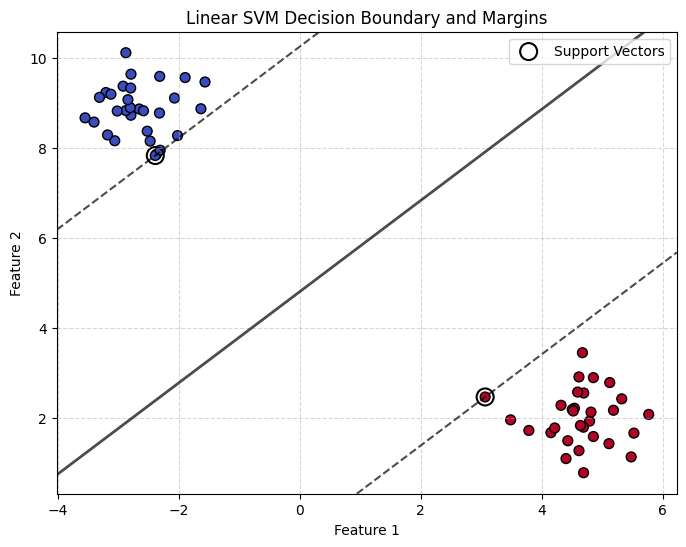

In [12]:
#Q7.Implement support vector machine for linearly seperable classes and visulaize the margins and decision boundary

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# 1. Generate a linearly separable dataset
X, y = make_blobs(n_samples=60, centers=2, random_state=42, cluster_std=0.60)

# 2. Train a Linear SVM Classifier
clf = SVC(kernel='linear', C=1.0)
clf.fit(X, y)

# 3. Visualize Decision Boundary, Margins, and Support Vectors
plt.figure(figsize=(8, 6))

# Plot data points
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=50, edgecolors='k')

# Create a mesh grid to plot decision function
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf.decision_function(xy).reshape(XX.shape)

# Plot decision boundary (middle line) and margins (dashed lines at -1 and 1)
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.7,
           linestyles=['--', '-', '--'], linewidths=[1.5, 2, 1.5])

# Highlight support vectors (the points closest to the margin boundary)
ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=150,
           linewidth=1.5, facecolors='none', edgecolors='k', label='Support Vectors')

plt.title("Linear SVM Decision Boundary and Margins")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
